# Multiway number partitioning on qutrits — Sec. III B

This notebook regenerates, from the data in [`data/`](data/), everything the manuscript reports for the
balanced multiway number partitioning (MWNP) problem:

| Output | In the manuscript |
|---|---|
| `figures/final_energy.pdf` | Fig. 6 — final energy as a function of the number of qutrits |
| `figures/energy_convergence.pdf` | Fig. 7 — energy as a function of the number of variational parameters |
| tables printed below | the numbers quoted in the text of Sec. III B |
| LaTeX rows printed at the end | the instance table of Appendix C |

It only reads data; no simulation is run. Figure numbers refer to the current version of the manuscript.

**Conventions.** Energies are expectation values of the cost Hamiltonian of Eq. (33). Every instance has a
perfect partition, so the ground-state energy is $E_0=0$ and the energy directly measures the deviation from
the optimal solution. The initial state $|\phi_g\rangle=|+_3\rangle^{\otimes n}$ has energy
$\langle\phi_g|H_C|\phi_g\rangle=\tfrac23\sum_i s_i^2$.

In [1]:
import json
import shutil
import subprocess
from collections import defaultdict
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt


def latex_with_txfonts():
    """The manuscript figures are rendered with LaTeX and the txfonts package."""
    if shutil.which("latex") is None or shutil.which("kpsewhich") is None:
        return False
    found = subprocess.run(["kpsewhich", "txfonts.sty"], capture_output=True, text=True).stdout
    return bool(found.strip())


USE_TEX = latex_with_txfonts()   # falls back to the STIX fonts, which look very similar

mpl.rcdefaults()
mpl.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})
if USE_TEX:
    mpl.rcParams.update({
        "text.usetex": True,
        "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}\usepackage{bm}\usepackage{txfonts}",
    })
else:
    mpl.rcParams.update({"mathtext.fontset": "stix", "font.serif": ["STIXGeneral"]})

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
print("LaTeX rendering:", USE_TEX)

LaTeX rendering: True


## Data

| File | Contents |
|---|---|
| `instances.json` | 20 instances per size $n=5,\dots,12$: the numbers, their unique optimal partition |
| `adapt_runs.json` | 1600 Qudit-ADAPT runs: 8 sizes × 2 pools ($l=1,2$) × 20 instances × 5 orderings of the numbers |
| `qaoa_interp.json` | qudit QAOA with INTERP initialization, energy at every depth $p=1,\dots,40$ |
| `qaoa_random_restarts_p40.json` | qudit QAOA at $p=40$ from 10 random initializations per instance |

Each file carries a `description` field and, where relevant, the `settings` used to produce it.

In [2]:
DATA = Path("data")
load = lambda name: json.load(open(DATA / name, encoding="utf-8"))

instances = load("instances.json")["instances"]
adapt = load("adapt_runs.json")
interp = load("qaoa_interp.json")["runs"]
random_restarts = load("qaoa_random_restarts_p40.json")["runs"]

SIZES = list(range(5, 13))
K_MAX = adapt["settings"]["max_parameters"]
print(adapt["settings"])
print(len(instances), "instances,", len(adapt["runs"]), "ADAPT runs,",
      len(interp), "INTERP chains,", len(random_restarts), "random-restart sets")

{'gradient_threshold': 0.001, 'max_parameters': 80, 'initial_state': '|+_3>^n', 'mixer': 'H_M = -sum_j [sqrt(2) Lx_j + Lz_j^2]', 'optimizer': 'BFGS with analytic gradient (gtol 1e-10)', 'initialization': 'warm start (theta*_{k-1}, 0)'}
160 instances, 1600 ADAPT runs, 160 INTERP chains, 160 random-restart sets


In [3]:
# Initial-state energy of every instance
e_init = {(i["n"], i["instance"]): 2 / 3 * sum(s * s for s in i["numbers"]) for i in instances}

# Qudit-ADAPT: final energy of every run, and the full trace of the ascending ordering (ordering 0).
# A run that stops before 80 parameters keeps its final energy for the remaining parameter counts.
adapt_final = defaultdict(list)          # (n, l, instance) -> final energies of the 5 orderings
adapt_trace = {}                         # (n, l, instance) -> energy after k = 0..80 operators
adapt_capped = defaultdict(list)         # (n, l) -> whether each run used all 80 parameters
for r in adapt["runs"]:
    e = r["energy"]
    adapt_final[(r["n"], r["l"], r["instance"])].append(e[-1])
    adapt_capped[(r["n"], r["l"])].append(r["stop_reason"] == "max_parameters")
    if r["ordering"] == 0:
        adapt_trace[(r["n"], r["l"], r["instance"])] = np.array(e + [e[-1]] * (K_MAX + 1 - len(e)))

# Qudit QAOA with INTERP: energy at p = 1..40 (2p parameters)
qaoa_trace = {(r["n"], r["instance"]): np.array(r["energy_per_depth"]) for r in interp}
qaoa_final = {key: trace[-1] for key, trace in qaoa_trace.items()}

def per_instance(n, method):
    """Final energy of the 20 instances of size n; Qudit-ADAPT is averaged over the 5 orderings."""
    if method == "qaoa":
        return np.array([qaoa_final[(n, i)] for i in range(20)])
    l = {"l1": 1, "l2": 2}[method]
    return np.array([np.mean(adapt_final[(n, l, i)]) for i in range(20)])

## Fig. 6 — final energy

Small markers are the 20 instances of each size (for Qudit-ADAPT, the average over the five orderings of the
numbers); large markers joined by dashed lines are the averages over instances. The vertical axis is
logarithmic above 1 and linear below, so that the exact solution, $E=0$, is visible.

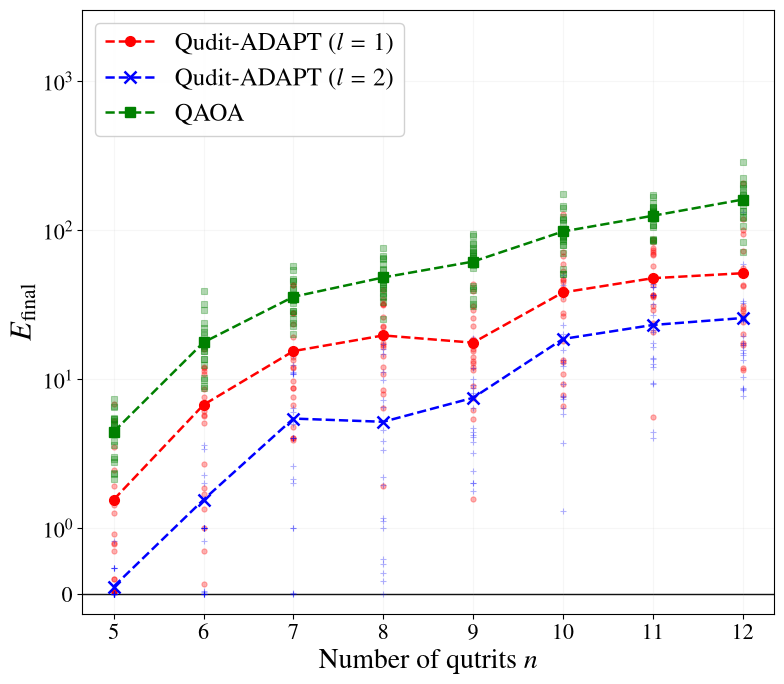

In [4]:
METHODS = {
    "l1":   dict(color="red",   marker="o", ms=7,           label=r"Qudit-ADAPT ($l=1$)"),
    "l2":   dict(color="blue",  marker="x", ms=8, mew=1.8,  label=r"Qudit-ADAPT ($l=2$)"),
    "qaoa": dict(color="green", marker="s", ms=7,           label=r"QAOA"),
}

fig, ax = plt.subplots(figsize=(8, 7))
for method, style in METHODS.items():
    means = []
    for n in SIZES:
        values = per_instance(n, method)
        ax.scatter(np.full(len(values), n), values, s=14, color=style["color"], alpha=0.30,
                   marker="+" if style["marker"] == "x" else style["marker"], linewidths=0.8, zorder=2)
        means.append(values.mean())
    ax.plot(SIZES, means, linestyle="--", linewidth=1.8, zorder=3, **style)

ax.axhline(0, color="black", linewidth=1.0, zorder=1)
ax.set_yscale("symlog", linthresh=1, linscale=0.4)
ax.set_ylim(-0.3, 3e3)
ax.set_xticks(SIZES)
ax.set_xlabel(r"Number of qutrits $n$", fontsize=20)
ax.set_ylabel(r"$E_{\mathrm{final}}$", fontsize=22)
ax.tick_params(axis="both", which="major", labelsize=16)
ax.grid(True, which="both", alpha=0.1)
ax.legend(loc="upper left", fontsize=18, frameon=True, framealpha=0.9)
fig.tight_layout()
fig.savefig(FIGURES / "final_energy.pdf")
plt.show()

## Fig. 7 — energy as a function of the number of variational parameters

Thin lines are individual instances (ascending ordering of the numbers for Qudit-ADAPT); thick lines are the
median over the 20 instances. Each QAOA layer adds two parameters.

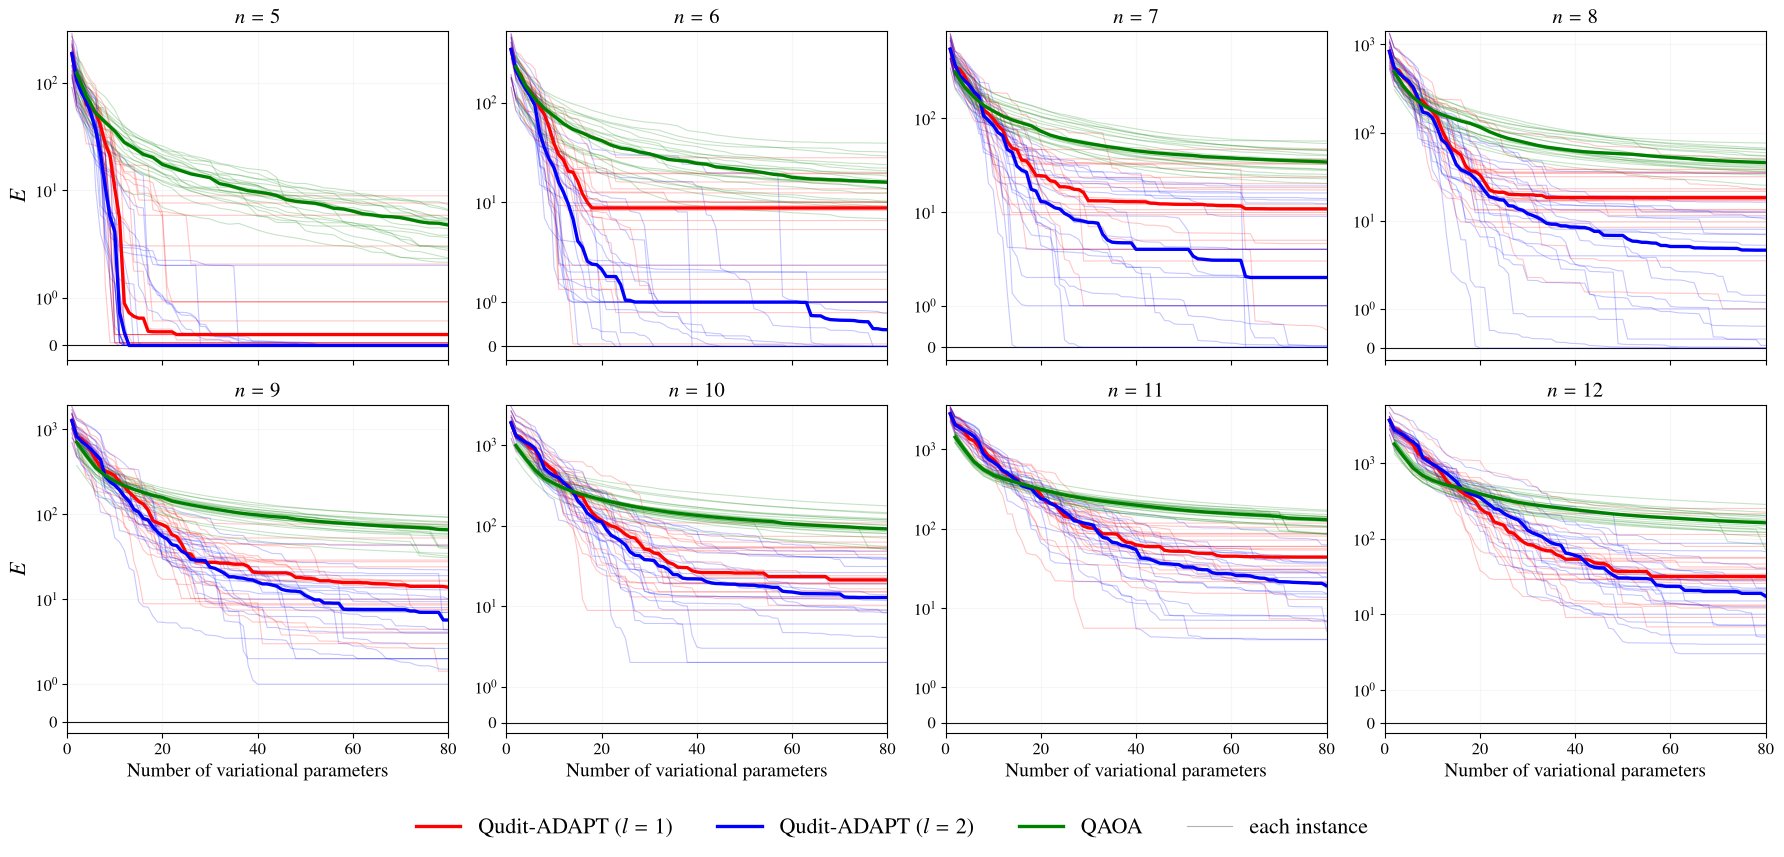

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5), sharex=True)
k = np.arange(1, K_MAX + 1)
for ax, n in zip(axes.flat, SIZES):
    curves = {
        "l1": (k, [adapt_trace[(n, 1, i)][1:] for i in range(20)]),
        "l2": (k, [adapt_trace[(n, 2, i)][1:] for i in range(20)]),
        "qaoa": (2 * np.arange(1, 41), [qaoa_trace[(n, i)] for i in range(20)]),
    }
    for method, (x, ys) in curves.items():
        color = METHODS[method]["color"]
        for y in ys:
            ax.plot(x, y, color=color, alpha=0.22, linewidth=0.8, zorder=2)
        ax.plot(x, np.median(np.array(ys), axis=0), color=color, linewidth=2.4, zorder=3)
    ax.axhline(0, color="black", linewidth=0.8, zorder=1)
    ax.set_yscale("symlog", linthresh=1, linscale=0.4)
    ax.set_ylim(-0.3, None)
    ax.set_xlim(0, K_MAX)
    ax.set_title(rf"$n={n}$", fontsize=15)
    ax.tick_params(axis="both", which="major", labelsize=12)
    ax.grid(True, which="major", alpha=0.1)
for ax in axes[1]:
    ax.set_xlabel("Number of variational parameters", fontsize=14)
for ax in axes[:, 0]:
    ax.set_ylabel(r"$E$", fontsize=16)
handles = [plt.Line2D([], [], color=s["color"], linewidth=2.4, label=s["label"]) for s in METHODS.values()]
handles.append(plt.Line2D([], [], color="gray", linewidth=0.8, alpha=0.6, label="each instance"))
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=16, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(FIGURES / "energy_convergence.pdf")
plt.show()

## Numbers quoted in Sec. III B

All averages are over the 20 instances of each size; "wins" count instances. "Exact" means a final energy
below $10^{-3}$, counted over the 100 runs (20 instances × 5 orderings) of each size.

In [6]:
header = (f"{'n':>2} {'E_init':>7} | {'<E> l=1':>8} {'<E> l=2':>8} {'<E> QAOA':>8} | "
          f"{'QAOA/l1':>7} {'QAOA/l2':>7} {'l1/l2':>6} | {'l1<QAOA':>7} {'l2<QAOA':>7} {'l2<l1':>5} | "
          f"{'%init l1':>8} {'%init l2':>8} {'%init QAOA':>10} | {'exact l2':>8} {'cap l2':>6}")
print(header)
print("-" * len(header))
totals = defaultdict(int)
summary = {}
for n in SIZES:
    e0 = np.mean([e_init[(n, i)] for i in range(20)])
    l1, l2, q = per_instance(n, "l1"), per_instance(n, "l2"), per_instance(n, "qaoa")
    runs_l2 = [e for i in range(20) for e in adapt_final[(n, 2, i)]]
    row = dict(e0=e0, l1=l1.mean(), l2=l2.mean(), q=q.mean(),
               win1=int(np.sum(l1 < q)), win2=int(np.sum(l2 < q)), win21=int(np.sum(l2 < l1)),
               exact2=np.mean(np.array(runs_l2) < 1e-3), cap2=np.mean(adapt_capped[(n, 2)]))
    summary[n] = row
    for key in ("win1", "win2", "win21"):
        totals[key] += row[key]
    print(f"{n:2d} {e0:7.0f} | {row['l1']:8.2f} {row['l2']:8.3f} {row['q']:8.2f} | "
          f"{row['q']/row['l1']:7.1f} {row['q']/row['l2']:7.1f} {row['l1']/row['l2']:6.1f} | "
          f"{row['win1']:>4}/20 {row['win2']:>4}/20 {row['win21']:>2}/20 | "
          f"{100*row['l1']/e0:7.1f}% {100*row['l2']/e0:7.2f}% {100*row['q']/e0:9.1f}% | "
          f"{100*row['exact2']:7.0f}% {100*row['cap2']:5.0f}%")

ratio = lambda a, b: [summary[n][a] / summary[n][b] for n in SIZES]
pct = lambda a: [100 * summary[n][a] / summary[n]["e0"] for n in SIZES]
print()
print(f"l=2 lower than QAOA in {totals['win2']}/160 instances; l=1 in {totals['win1']}/160; "
      f"l=2 lower than l=1 in {totals['win21']}/160")
print(f"QAOA / l=2 average final energy: {min(ratio('q', 'l2')):.1f} to {max(ratio('q', 'l2')):.1f}")
print(f"QAOA / l=1 average final energy: {min(ratio('q', 'l1')):.1f} to {max(ratio('q', 'l1')):.1f}")
print(f"final energy relative to the initial state: l=1 {min(pct('l1')):.1f}-{max(pct('l1')):.1f} %, "
      f"l=2 below {max(pct('l2')):.2f} %, QAOA {min(pct('q')):.1f}-{max(pct('q')):.1f} %")
print(f"l=1 / l=2: {summary[5]['l1']/summary[5]['l2']:.0f} at n=5, "
      f"{min(ratio('l1', 'l2')[5:]):.1f}-{max(ratio('l1', 'l2')[5:]):.1f} for n>=10")

 n  E_init |  <E> l=1  <E> l=2 <E> QAOA | QAOA/l1 QAOA/l2  l1/l2 | l1<QAOA l2<QAOA l2<l1 | %init l1 %init l2 %init QAOA | exact l2 cap l2
-----------------------------------------------------------------------------------------------------------------------------------------
 5     235 |     1.56    0.120     4.44 |     2.9    37.0   13.0 |   18/20   20/20 19/20 |     0.7%    0.05%       1.9% |      94%     5%
 6     409 |     6.73    1.554    17.67 |     2.6    11.4    4.3 |   20/20   20/20 18/20 |     1.6%    0.38%       4.3% |      35%    16%
 7     693 |    15.44    5.442    35.72 |     2.3     6.6    2.8 |   18/20   20/20 17/20 |     2.2%    0.79%       5.2% |      21%    18%
 8    1046 |    19.66    5.178    48.16 |     2.4     9.3    3.8 |   19/20   20/20 19/20 |     1.9%    0.50%       4.6% |      11%    61%
 9    1486 |    17.58    7.500    61.52 |     3.5     8.2    2.3 |   20/20   20/20 17/20 |     1.2%    0.50%       4.1% |       1%    51%
10    2281 |    38.20   18.614    

## Why INTERP: QAOA from random parameters

At $p=40$, ten optimizations from random angles per instance end close to the energy of the initial state for
$n\geq10$, whereas INTERP reaches far lower energies.

In [7]:
print(f"{'n':>2} | {'best of 10 / E_init':>19} | {'INTERP / E_init':>15} | {'best of 10 / INTERP':>19}")
for n in SIZES:
    best = np.array([min(r["final_energy"]) for r in random_restarts if r["n"] == n])
    e0 = np.array([e_init[(n, i)] for i in range(20)])
    q = per_instance(n, "qaoa")
    print(f"{n:2d} | {best.mean() / e0.mean():19.3f} | {q.mean() / e0.mean():15.3f} | {best.mean() / q.mean():19.1f}")

 n | best of 10 / E_init | INTERP / E_init | best of 10 / INTERP
 5 |               0.101 |           0.019 |                 5.3
 6 |               0.353 |           0.043 |                 8.2
 7 |               0.585 |           0.052 |                11.3
 8 |               0.718 |           0.046 |                15.6
 9 |               0.865 |           0.041 |                20.9
10 |               1.012 |           0.043 |                23.6
11 |               0.990 |           0.038 |                25.9
12 |               0.998 |           0.038 |                26.2


## Appendix C — representative instances

The first two instances of each size, with their unique optimal partition, as LaTeX table rows.

In [8]:
def subset(numbers):
    return r"\{" + ",".join(map(str, numbers)) + r"\}"

for n in SIZES:
    for inst in [i for i in instances if i["n"] == n][:2]:
        parts = sorted(inst["optimal_subsets"], key=lambda s: (len(s), s))
        assert all(sum(p) == inst["subset_sum"] for p in parts)
        print(f"{n} & ${subset(inst['numbers'])}$ & ${r'\;|\;'.join(subset(p) for p in parts)}$ "
              f"& {inst['subset_sum']} \\\\")

5 & $\{2,3,7,8,10\}$ & $\{10\}\;|\;\{2,8\}\;|\;\{3,7\}$ & 10 \\
5 & $\{1,4,6,9,10\}$ & $\{10\}\;|\;\{1,9\}\;|\;\{4,6\}$ & 10 \\
6 & $\{1,6,8,10,12,17\}$ & $\{1,17\}\;|\;\{6,12\}\;|\;\{8,10\}$ & 18 \\
6 & $\{4,6,7,8,11,18\}$ & $\{18\}\;|\;\{7,11\}\;|\;\{4,6,8\}$ & 18 \\
7 & $\{1,4,6,10,13,16,19\}$ & $\{4,19\}\;|\;\{10,13\}\;|\;\{1,6,16\}$ & 23 \\
7 & $\{3,5,6,9,11,17,18\}$ & $\{5,18\}\;|\;\{6,17\}\;|\;\{3,9,11\}$ & 23 \\
8 & $\{8,9,10,11,12,14,16,19\}$ & $\{14,19\}\;|\;\{8,9,16\}\;|\;\{10,11,12\}$ & 33 \\
8 & $\{5,6,8,9,14,16,17,24\}$ & $\{9,24\}\;|\;\{16,17\}\;|\;\{5,6,8,14\}$ & 33 \\
9 & $\{1,2,5,6,7,8,20,21,26\}$ & $\{6,26\}\;|\;\{5,7,20\}\;|\;\{1,2,8,21\}$ & 32 \\
9 & $\{2,3,4,6,8,9,12,23,26\}$ & $\{8,23\}\;|\;\{2,3,26\}\;|\;\{4,6,9,12\}$ & 31 \\
10 & $\{2,3,12,15,16,17,18,22,27,30\}$ & $\{2,22,30\}\;|\;\{12,15,27\}\;|\;\{3,16,17,18\}$ & 54 \\
10 & $\{2,9,18,22,23,24,25,26,28,30\}$ & $\{18,25,26\}\;|\;\{22,23,24\}\;|\;\{2,9,28,30\}$ & 69 \\
11 & $\{10,11,17,18,19,22,24,26,29,31,33\}